# LSB Matching Revisited

Jarno Mielikainen, IEEE SIGNAL PROCESSING LETTERS, VOL. 13, NO. 5, MAY 2006

## Overview

The paper modifies LSB matching, a steganographic method that hides message bits in the least significant bits (LSBs) of image pixels.

- **LSB replacement** overwrites the LSB of a pixel with a message bit. Even values can only grow by 1 and odd values can only drop by 1, so the embedding distortion is asymmetric and the method is easy to detect statistically
- **LSB matching** leaves a pixel untouched when its LSB already equals the message bit, otherwise it randomly adds or subtracts 1. There is no asymmetry, but the random choice of `+1`/`-1` carries no information; on average 0.5 pixels per pixel are changed
- **LSB matching revisited (LSBMR)** uses this choice to carry information. Pixels are processed in pairs `(x_i, x_i+1)`. After embedding, the first message bit is the LSB of the stego pixel `y_i`, and the second message bit is a binary function of both stego pixels

```
m_i = LSB(y_i)
m_i+1 = f(y_i, y_i+1) = LSB(floor(y_i / 2) + y_i+1)
```

The payload is the same as in LSB matching (1 bit per pixel), but fewer pixels are changed. If message bits and cover LSBs are equally likely, the expected number of modifications per pixel is

```
(P(x_i != m_i) + P(x_i = m_i) * P(f(x_i, x_i+1) != m_i+1)) / 2 = (0.5 + 0.5 * 0.5) / 2 = 0.375
```

Pixels are visited in a pseudo-random order generated from a secret key (as in LSB matching, Sharp 2001). Extraction needs only the stego image, the key and the number of hidden bits. The method is not reversible: the cover image cannot be restored.

The paper describes grayscale images. In this approach we will treat each channel (R, G, B) as a separate 8-bit image.

The paper also evaluates the method with steganalysis (ROC curves of the calibrated HCF COM detectors). Here we reproduce the other measurements: modifications per pixel and the even/odd region imbalance.

## Data preparation

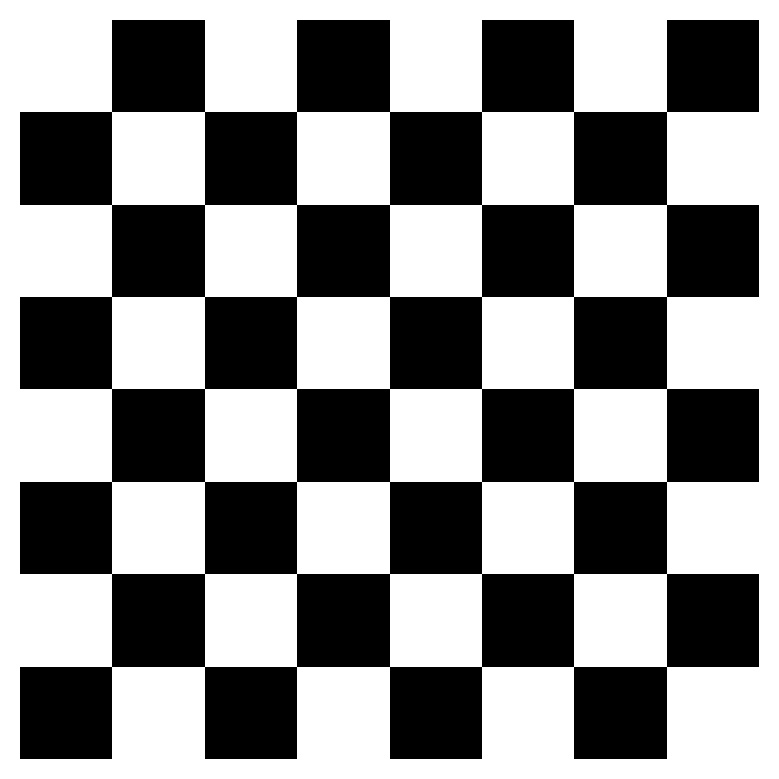

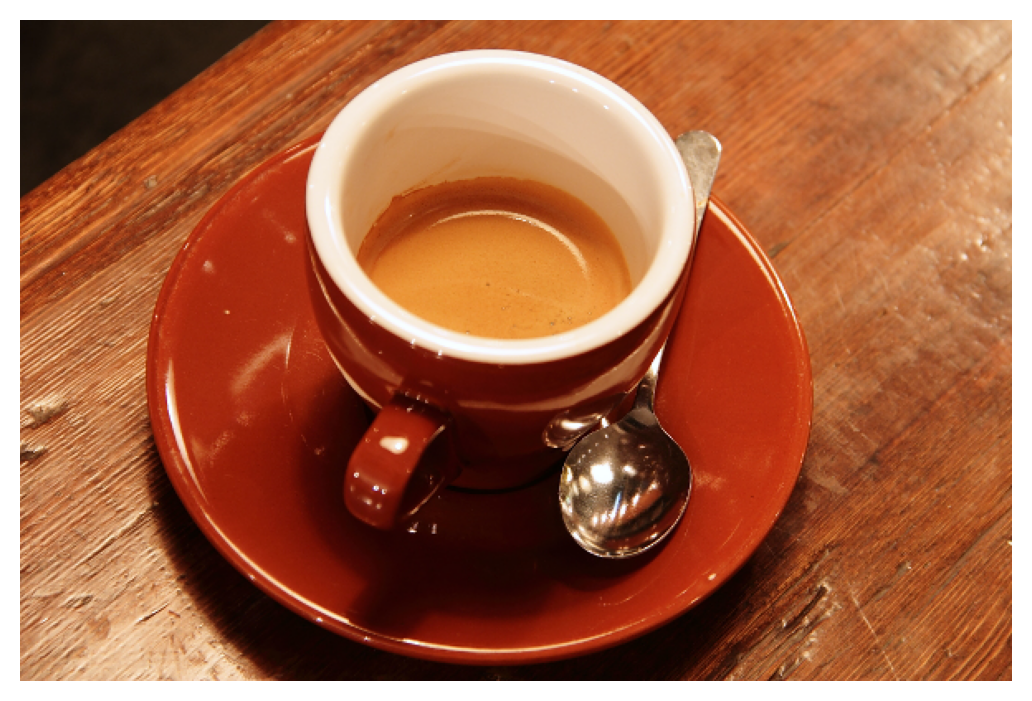

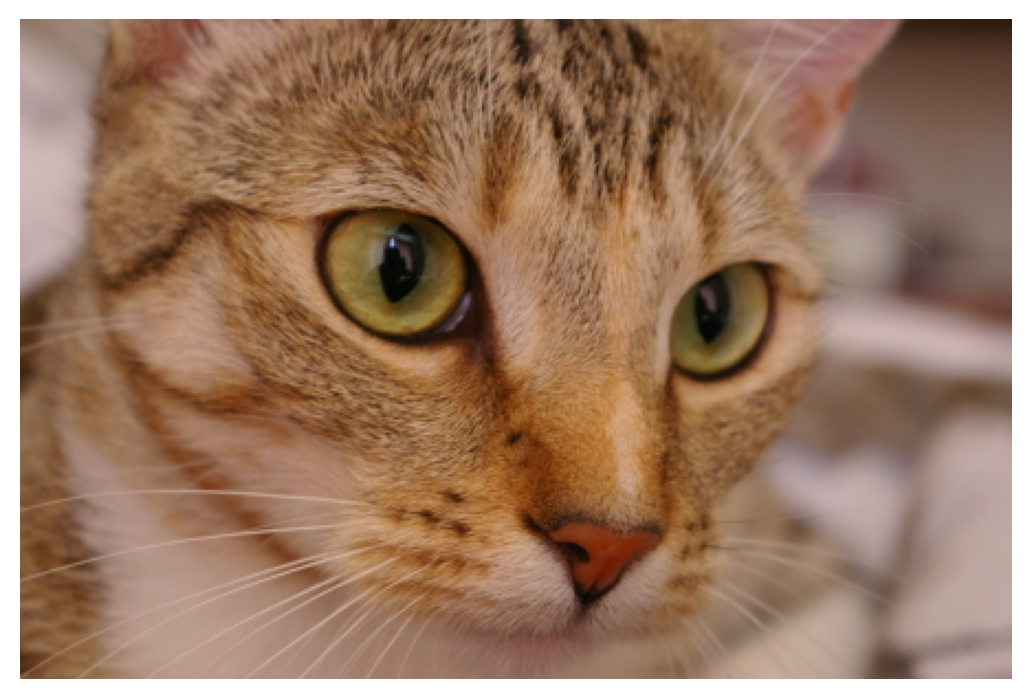

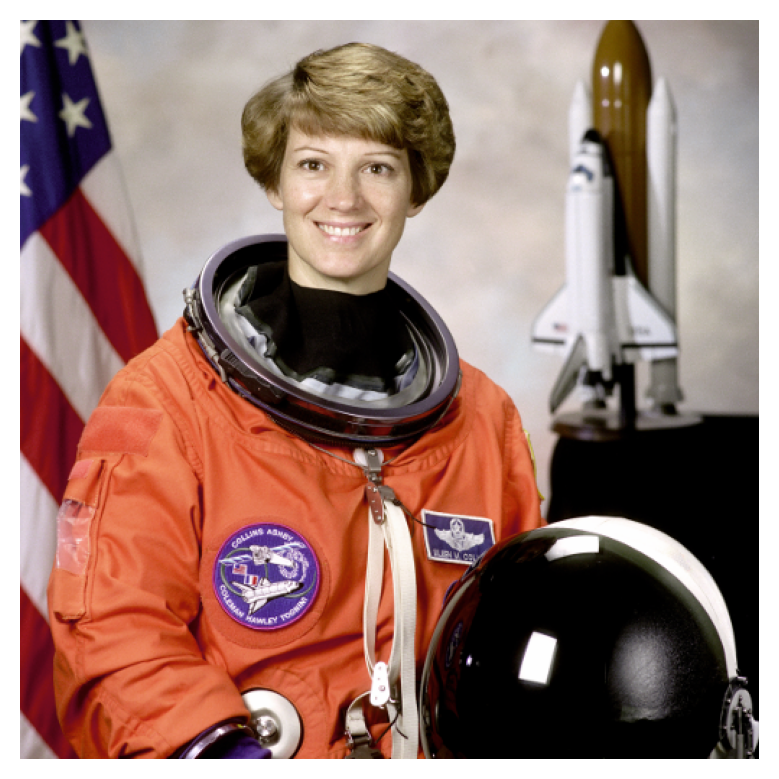

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from skimage import data

checkerboard = (data.checkerboard() > 127).astype(np.uint8) * 255
checkerboard = np.repeat(checkerboard[..., np.newaxis], 3, axis=-1)

imgs_color = [checkerboard, data.coffee(), data.cat(), data.astronaut()]
image_names = ["checkerboard", "coffee", "cat", "astronaut"]

for img in imgs_color:
    plt.imshow(img)
    plt.axis('off')
    plt.show()

## Implementation

### Pairs, relation function and embedding order

1. Split the flattened channel into non-overlapping units of two consecutive pixels `(x_i, x_i+1)`; if the pixel count is odd, the last pixel is left untouched
2. Each pair hides 2 bits: the first is `LSB(x_i)`, the second is the relation `f(x_i, x_i+1) = LSB(floor(x_i / 2) + x_i+1)`
3. `f` has the properties required by the paper:
    - `f(y, z) != f(y - 1, z)` and `f(y, z) != f(y + 1, z)` for a pixel whose LSB must change: `x_i - 1` and `x_i + 1` both have the right LSB, but they give opposite values of `f`, so exactly one of them hides the second bit
    - `f(y, z) != f(y, z + 1)` and `f(y, z) != f(y, z - 1)`: both `+1` and `-1` on the second pixel flip `f`
4. The pairs are visited in an order given by a pseudo-random permutation seeded with a secret `key`

In [2]:
channel_names = ["R", "G", "B"]
key = 2006
rng = np.random.default_rng(42)  # fixed seed - reproducible payloads and +1/-1 choices

# split channel into pairs of pixels
def split_into_pairs(channel):
    flat = channel.ravel().astype(np.int16)
    return flat[:len(flat) // 2 * 2].reshape(-1, 2)

# second hidden bit - relation between two pixels
def pixel_relation(first_pixel, second_pixel):
    return ((first_pixel // 2) + second_pixel) % 2

# pseudo-random order of units, the same key gives the same order during extraction
def embedding_order(unit_count, key):
    return np.random.default_rng(key).permutation(unit_count)

In [3]:
# the relation flips for +1/-1 on the second pixel and for exactly one of x_i - 1, x_i + 1
first_pixel, second_pixel = 100, 162
print(f"f(x_i, x_i+1)      = {pixel_relation(first_pixel, second_pixel)}")
print(f"f(x_i - 1, x_i+1)  = {pixel_relation(first_pixel - 1, second_pixel)}")
print(f"f(x_i + 1, x_i+1)  = {pixel_relation(first_pixel + 1, second_pixel)}")
print(f"f(x_i, x_i+1 - 1)  = {pixel_relation(first_pixel, second_pixel - 1)}")
print(f"f(x_i, x_i+1 + 1)  = {pixel_relation(first_pixel, second_pixel + 1)}")

f(x_i, x_i+1)      = 0
f(x_i - 1, x_i+1)  = 1
f(x_i + 1, x_i+1)  = 0
f(x_i, x_i+1 - 1)  = 1
f(x_i, x_i+1 + 1)  = 1


### Embedding and extraction for one pair

Embedding of bits `(m_i, m_i+1)` into `(x_i, x_i+1)`:
1. `LSB(x_i) != m_i` - `x_i+1` stays, `x_i` becomes `x_i - 1` if `f(x_i - 1, x_i+1) = m_i+1`, otherwise `x_i + 1`
2. `LSB(x_i) = m_i` and `f(x_i, x_i+1) = m_i+1` - nothing to change
3. `LSB(x_i) = m_i` and `f(x_i, x_i+1) != m_i+1` - `x_i` stays, `x_i+1` is changed by `+1` or `-1`. The sign is chosen separately for the even and odd valued regions (parity of the cover pixel) so that the sum of differences between cover and stego in each region stays close to 0 - this is what removes the LSB replacement style imbalance. We keep a running sum of signed changes per region and pick the sign that pushes it back towards 0 (random on a tie)
4. A pixel value must stay in `[0, 255]`. If the needed `x_i - 1` or `x_i + 1` is outside the range, the other neighbour is used (it has the right LSB too); when `f` then does not match, `x_i+1` is additionally changed by `+-1` (rare: only for pixels equal to 0 or 255)

Extraction needs only the stego pair: the bits are `LSB(y_i)` and `f(y_i, y_i+1)`

In [4]:
# sign of the change of the second pixel - keeps the sum of differences in the region close to 0
def choose_step(pixel, balance):
    if pixel == 0:
        return 1
    if pixel == 255:
        return -1
    region_balance = balance[pixel % 2]
    if region_balance > 0:
        return -1
    if region_balance < 0:
        return 1
    return int(rng.choice([-1, 1]))

def embed_pair(first_pixel, second_pixel, bits, balance):
    first_bit, second_bit = bits
    new_first, new_second = first_pixel, second_pixel

    if first_pixel % 2 != first_bit:
        # LSB must change - exactly one of the neighbours also gives the right relation
        if pixel_relation(first_pixel - 1, second_pixel) == second_bit:
            new_first = first_pixel - 1
        else:
            new_first = first_pixel + 1

        # keep the pixel in range, the other neighbour has the same LSB
        if not 0 <= new_first <= 255:
            new_first = 2 * first_pixel - new_first

    # relation does not match (LSB was right, or the range fix broke it) - change the second pixel
    if pixel_relation(new_first, second_pixel) != second_bit:
        new_second = second_pixel + choose_step(second_pixel, balance)

    return new_first, new_second

In [5]:
def extract_pair(first_pixel, second_pixel):
    return [first_pixel % 2, pixel_relation(first_pixel, second_pixel)]

In [6]:
# all four bit combinations for the same pair
pair = (100, 162)
balance = np.zeros(2, dtype=int)
for bits in [(0, 0), (0, 1), (1, 0), (1, 1)]:
    new_pair = embed_pair(*pair, bits, balance)
    print(f"pair={pair}, bits to hide={bits} -> stego pair={new_pair}, extracted={extract_pair(*new_pair)}")

pair=(100, 162), bits to hide=(0, 0) -> stego pair=(100, 162), extracted=[0, 0]
pair=(100, 162), bits to hide=(0, 1) -> stego pair=(100, 161), extracted=[0, 1]
pair=(100, 162), bits to hide=(1, 0) -> stego pair=(101, 162), extracted=[1, 0]
pair=(100, 162), bits to hide=(1, 1) -> stego pair=(99, 162), extracted=[1, 1]


### Embedding and extraction for a channel

The payload is hidden in pairs taken in the pseudo-random order; each pair hides 2 bits and an odd payload is padded with one zero. The capacity is 2 bits per pair, i.e. 1 bit per pixel. `balance` stores the sum of `stego - cover` over the even and the odd cover pixels changed so far.

Extraction takes the same pairs in the same order and reads `LSB(y_i)` and `f(y_i, y_i+1)` from each.

In [7]:
def embed_channel(channel, bits, key):

    # split channel into pairs of pixels
    pairs = split_into_pairs(channel)

    # pad an odd payload with one zero, since each pair hides 2 bits
    bits = np.asarray(bits).tolist()
    bits += [0] * (len(bits) % 2)
    if len(bits) > 2 * len(pairs):
        raise ValueError(f"Payload of {len(bits)} bits exceeds capacity {2 * len(pairs)}")

    marked_pairs = pairs.copy()

    # running sum of (stego - cover) in the even and odd valued region
    balance = np.zeros(2, dtype=int)

    # hide 2 bits in each pair, visited in the key-dependent order
    order = embedding_order(len(pairs), key)
    for pair_index, bit_index in zip(order, range(0, len(bits), 2)):
        first_pixel, second_pixel = (int(pixel) for pixel in pairs[pair_index])
        new_first, new_second = embed_pair(first_pixel, second_pixel, bits[bit_index:bit_index + 2], balance)

        balance[first_pixel % 2] += new_first - first_pixel
        balance[second_pixel % 2] += new_second - second_pixel
        marked_pairs[pair_index] = (new_first, new_second)

    # put the marked pairs back into the channel
    marked = channel.ravel().copy()
    marked[:marked_pairs.size] = marked_pairs.ravel()
    return marked.reshape(channel.shape)

In [8]:
def extract_channel(marked_channel, bit_count, key):
    pairs = split_into_pairs(marked_channel)

    # take the same pairs in the same order as during embedding
    order = embedding_order(len(pairs), key)
    used_pairs = pairs[order[:(bit_count + 1) // 2]]

    # first bit - LSB of the first pixel, second bit - relation of both pixels
    bits = np.stack([used_pairs[:, 0] % 2, pixel_relation(used_pairs[:, 0], used_pairs[:, 1])], axis=1)
    return bits.ravel()[:bit_count]

### Baselines: LSB replacement and LSB matching

For comparison we also implement both methods described in the introduction of the paper. They use the same key, so the pixels are visited in the same pseudo-random order. Each pixel hides 1 bit.

In [9]:
def lsb_replacement(channel, bits, key):
    flat = channel.ravel().copy()
    positions = embedding_order(flat.size, key)[:len(bits)]
    # overwrite the LSB with the message bit
    flat[positions] = (flat[positions] & 0xFE) | np.asarray(bits, dtype=np.uint8)
    return flat.reshape(channel.shape)

def lsb_matching(channel, bits, key):
    flat = channel.ravel().astype(np.int16)
    positions = embedding_order(flat.size, key)[:len(bits)]
    pixels = flat[positions]

    # random +1/-1, forced at the edges of the range
    steps = rng.choice([-1, 1], size=len(positions))
    steps[pixels == 0] = 1
    steps[pixels == 255] = -1

    # change only pixels with LSB different from the message bit
    mismatch = pixels % 2 != np.asarray(bits)
    flat[positions[mismatch]] += steps[mismatch]
    return flat.astype(np.uint8).reshape(channel.shape)

# both baselines hide the bit in the LSB of the pixel
def extract_lsb(marked_channel, bit_count, key):
    flat = marked_channel.ravel()
    positions = embedding_order(flat.size, key)[:bit_count]
    return flat[positions] % 2

### Measures

The paper compares the methods using
- the number of modifications per pixel (expected: 0.500 for LSB matching and 0.375 for the new method)
- the absolute value of the sum of differences between cover and stego per pixel, computed separately for the even and odd valued regions of the cover image (0.500 for LSB replacement and 0.000 for the new method - no imbalance)

We additionally measure the Peak Signal-to-Noise Ratio (PSNR).

In [10]:
def modifications_per_pixel(cover, stego):
    return np.mean(cover != stego)

def region_imbalance(cover, stego):
    difference = stego.astype(np.int16) - cover.astype(np.int16)
    is_even = cover % 2 == 0
    even_imbalance = abs(difference[is_even].mean()) if is_even.any() else 0.0
    odd_imbalance = abs(difference[~is_even].mean()) if (~is_even).any() else 0.0
    return even_imbalance, odd_imbalance

## Usage

A random payload of the maximal length (1 bit per pixel, i.e. as much as the capacity of every method) is embedded into every channel with all three methods and then extracted for value comparison.

In [11]:
import pandas as pd
from IPython.display import display
from skimage.metrics import peak_signal_noise_ratio

methods = {
    "LSB replacement": (lsb_replacement, extract_lsb),
    "LSB matching": (lsb_matching, extract_lsb),
    "LSBMR": (embed_channel, extract_channel),
}

marked_images = {}  # LSBMR stego images
results = []

for image_name, image in zip(image_names, imgs_color):
    marked_channels = []

    for channel_index, channel_name in enumerate(channel_names):
        channel = image[:, :, channel_index]

        # maximal-length random payload: 1 bit per pixel (pixel count is even in all examples)
        capacity = 2 * len(split_into_pairs(channel))
        bits = rng.integers(0, 2, size=capacity)

        for method_name, (embed, extract) in methods.items():
            marked = embed(channel, bits, key)
            extracted_bits = extract(marked, len(bits), key)
            even_imbalance, odd_imbalance = region_imbalance(channel, marked)

            results.append({
                "image": image_name,
                "channel": channel_name,
                "method": method_name,
                "modifications/pixel": modifications_per_pixel(channel, marked),
                "even imbalance": even_imbalance,
                "odd imbalance": odd_imbalance,
                "PSNR [dB]": peak_signal_noise_ratio(channel, marked),
                "recovered": np.array_equal(extracted_bits, bits),
            })

            if method_name == "LSBMR":
                marked_channels.append(marked)

    marked_images[image_name] = np.stack(marked_channels, axis=-1)

results = pd.DataFrame(results)
print("All payloads recovered:", results["recovered"].all())

All payloads recovered: True


Values averaged over the channels of every image:

In [12]:
measures = ["modifications/pixel", "even imbalance", "odd imbalance", "PSNR [dB]"]

display(results.groupby(["image", "method"], sort=False)[measures].mean().round(3))

modifications/pixel  even imbalance  \
image        method                                                 
checkerboard LSB replacement                0.501           0.502   
             LSB matching                   0.501           0.502   
             LSBMR                          0.500           0.501   
coffee       LSB replacement                0.500           0.500   
             LSB matching                   0.500           0.006   
             LSBMR                          0.376           0.000   
cat          LSB replacement                0.498           0.498   
             LSB matching                   0.498           0.003   
             LSBMR                          0.375           0.000   
astronaut    LSB replacement                0.500           0.500   
             LSB matching                   0.500           0.102   
             LSBMR                          0.389           0.002   

                              odd imbalance  PSNR [dB]  
image        method                                     
checkerboard LSB replacement          0.500     51.134  
             LSB matching             0.500     51.134  
             LSBMR                    0.498     51.144  
coffee       LSB replacement          0.501     51.137  
             LSB matching             0.003     51.137  
             LSBMR                    0.000     52.374  
cat          LSB replacement          0.497     51.161  
             LSB matching             0.001     51.161  
             LSBMR                    0.000     52.389  
astronaut    LSB replacement          0.500     51.142  
             LSB matching             0.002     51.142  
             LSBMR                    0.000     52.233

Values averaged over the natural images (coffee, cat, astronaut) and all channels. The paper reports 0.500 / 0.375 modifications per pixel and 0.500 / 0.000 imbalance for LSB replacement / the new method:

In [13]:
natural = results[results["image"] != "checkerboard"]
display(natural.groupby("method", sort=False)[measures].mean().round(3))

,modifications/pixel,even imbalance,odd imbalance,PSNR [dB]
method,,,,
LSB replacement,0.499,0.499,0.499,51.147
LSB matching,0.499,0.037,0.002,51.147
LSBMR,0.380,0.001,0.000,52.332


The results agree with the paper: LSBMR changes ~0.375 pixels per pixel instead of 0.5 (so the PSNR is ~1.2 dB higher for the same payload), and its even/odd imbalance is ~0, the same as in LSB matching and unlike in LSB replacement.

Two deviations come from pixels at the edges of the range, where the sign of `+-1` is forced and cannot be chosen:
- **checkerboard** contains only the values 0 and 255. Every change of a pixel (0 can only grow, 255 can only drop) is forced, so LSBMR needs 0.5 modifications per pixel and shows the same imbalance as LSB replacement - there is no freedom that the method could use
- **astronaut** has large black areas with many pixels equal to 0, so a part of the changes is forced; the modifications per pixel grow slightly above 0.375 and LSB matching becomes visibly unbalanced (the imbalance of LSBMR stays low, since the sign of the free changes compensates it)

### Stego images

LSBMR changes pixels by at most 1 (apart from the rare range-edge fix), so the stego image looks the same as the cover. The right column shows the number of changed channels per pixel (white - all three channels are changed, black - none).

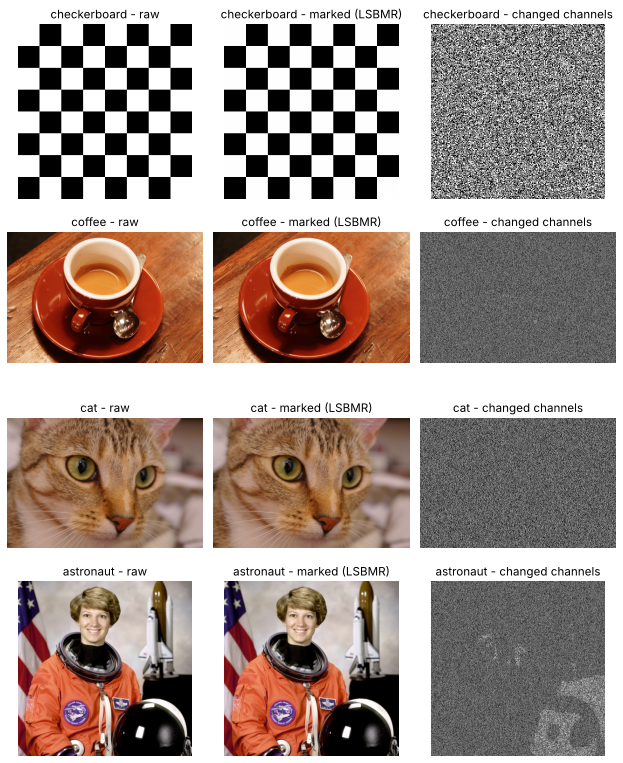

In [14]:
figure, axes = plt.subplots(len(imgs_color), 3, figsize=(9, 11), dpi=70)

for row, (image_name, image) in enumerate(zip(image_names, imgs_color)):
    marked = marked_images[image_name]
    changed_channels = np.sum(marked != image, axis=-1)

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"{image_name} - raw")
    axes[row, 1].imshow(marked)
    axes[row, 1].set_title(f"{image_name} - marked (LSBMR)")
    axes[row, 2].imshow(changed_channels, cmap="gray", vmin=0, vmax=3)
    axes[row, 2].set_title(f"{image_name} - changed channels")

for axis in axes.ravel():
    axis.axis("off")

plt.tight_layout()
plt.show()

### Modifications versus payload size

For a shorter payload only the first pairs (pixels) in the pseudo-random order are used. The number of modifications per pixel should grow linearly with the payload, with slope 0.5 for LSB matching and 0.375 for LSBMR.

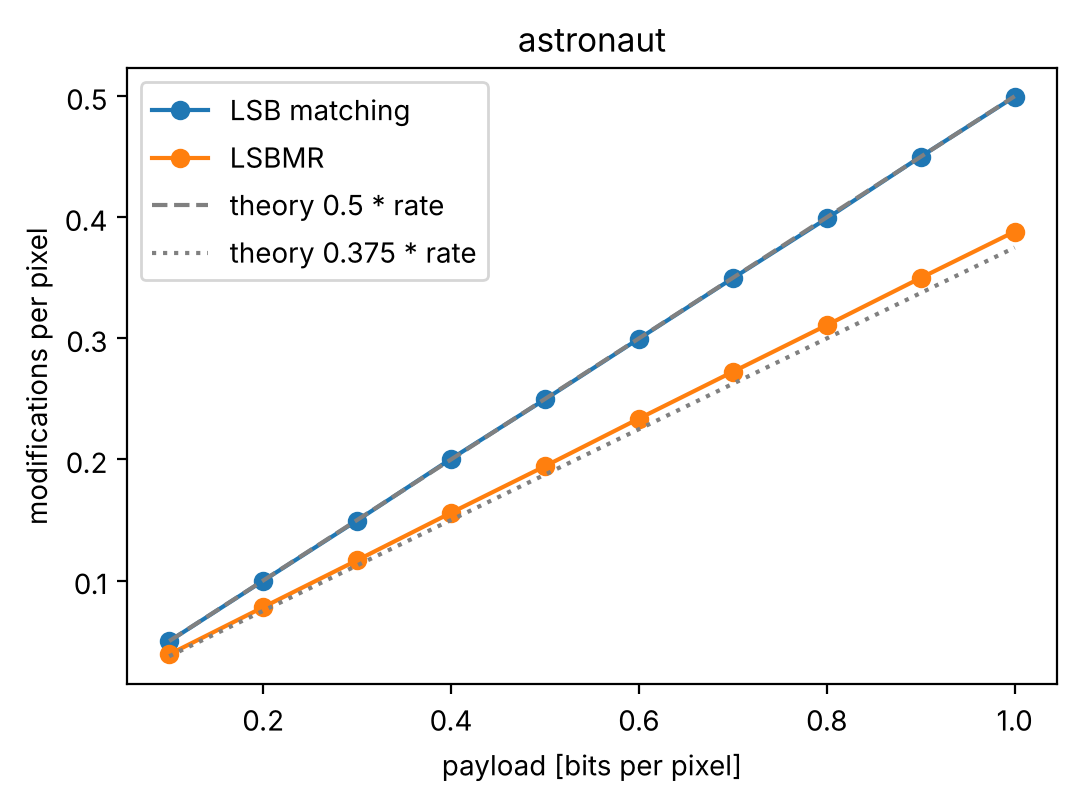

In [15]:
image_name = "astronaut"
image = imgs_color[image_names.index(image_name)]
payload_rates = np.linspace(0.1, 1.0, 10)  # bits per pixel

changes = {"LSB matching": [], "LSBMR": []}

for rate in payload_rates:
    measured = {method_name: [] for method_name in changes}

    for channel_index in range(3):
        channel = image[:, :, channel_index]
        bits = rng.integers(0, 2, size=int(rate * channel.size) // 2 * 2)

        measured["LSB matching"].append(modifications_per_pixel(channel, lsb_matching(channel, bits, key)))
        measured["LSBMR"].append(modifications_per_pixel(channel, embed_channel(channel, bits, key)))

    for method_name in changes:
        changes[method_name].append(np.mean(measured[method_name]))

plt.figure(figsize=(6, 4))
plt.plot(payload_rates, changes["LSB matching"], "o-", label="LSB matching")
plt.plot(payload_rates, changes["LSBMR"], "o-", label="LSBMR")
plt.plot(payload_rates, 0.5 * payload_rates, "--", color="gray", label="theory 0.5 * rate")
plt.plot(payload_rates, 0.375 * payload_rates, ":", color="gray", label="theory 0.375 * rate")
plt.xlabel("payload [bits per pixel]")
plt.ylabel("modifications per pixel")
plt.title(f"{image_name}")
plt.legend()
plt.show()